# Fall Detection Pipeline (Corrected Dataset Logic)
This notebook assumes:
- falling_01.csv to falling_20.csv => FALL class (1)
- no_falling.csv => NO FALL class (0)


In [ ]:
!pip install -q keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 6.9 MB/s eta 0:00:00


In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv1D,
    MaxPooling1D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# CHANGE THIS PATH IF NEEDED
DATA_DIR = "/content/drive/MyDrive/FYP/fall_detection"

def process_csi_string(csi_str):

    clean_str = csi_str.replace('[', '').replace(']', '').strip()

    clean_str = ' '.join(clean_str.split())

    csi_data = np.fromstring(
        clean_str,
        sep=' ',
        dtype=int
    )

    # Skip corrupted rows
    if len(csi_data) < 10:
        return None, None

    # Ensure even number of entries
    if len(csi_data) % 2 != 0:
        csi_data = csi_data[:-1]

    imag = csi_data[0::2]
    real = csi_data[1::2]

    amplitude = np.sqrt(imag**2 + real**2)

    phase = np.arctan2(imag, real)

    target_len = 128

    if len(amplitude) < target_len:

        padded_amp = np.zeros(target_len)
        padded_amp[:len(amplitude)] = amplitude
        amplitude = padded_amp

        padded_phase = np.zeros(target_len)
        padded_phase[:len(phase)] = phase
        phase = padded_phase

    elif len(amplitude) > target_len:

        amplitude = amplitude[:target_len]
        phase = phase[:target_len]

    return amplitude, phase

X = np.array(X_list)
X_phase = np.array(X_phase_list)
y = np.array(y_list)

print(f"\nTotal samples loaded: {X.shape[0]}")
print(f"Data shape: {X.shape}")
print(f"Labels shape: {y.shape}")

print("\nClass Distribution:")
print("No Fall (0):", np.sum(y == 0))
print("Fall (1):", np.sum(y == 1))

print("\nUnique Labels:", np.unique(y, return_counts=True))


Total samples loaded: 476
Data shape: (476, 128)
Labels shape: (476,)

Class Distribution:
No Fall (0): 261
Fall (1): 215

Unique Labels: (array([0, 1]), array([261, 215]))


In [ ]:
# Normalize Data

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# CNN Input Shape
X_scaled = X_scaled.reshape(
    X_scaled.shape[0],
    X_scaled.shape[1],
    1
)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (380, 128, 1)
Testing Shape: (96, 128, 1)


In [ ]:
# Build CNN Model

model = Sequential([

    Conv1D(
        32,
        kernel_size=3,
        activation='relu',
        input_shape=(128, 1)
    ),

    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Conv1D(
        64,
        kernel_size=3,
        activation='relu'
    ),

    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(1, activation='sigmoid')

])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 126, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 63, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 61, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1920)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       245,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 252,737 (987.25 KB)

 Trainable params: 252,545 (986.50 KB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
# Train Model

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 10s 389ms/step - accuracy: 0.8026 - loss: 0.5572 - val_accuracy: 0.9605 - val_loss: 0.5591
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9408 - loss: 0.3702 - val_accuracy: 0.9211 - val_loss: 0.5345
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9539 - loss: 0.1230 - val_accuracy: 0.9737 - val_loss: 0.5244
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9539 - loss: 0.1004 - val_accuracy: 0.9605 - val_loss: 0.4804
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9836 - loss: 0.0645 - val_accuracy: 0.9737 - val_loss: 0.4497
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9868 - loss: 0.0566 - val_accuracy: 0.9737 - val_loss: 0.4285
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9901 - loss: 0.0315 - val_accuracy: 0.9605 - val_loss: 0.4066
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9901 - loss: 0.0313 - val_accuracy: 0.9737 -

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step 
Accuracy: 0.9583333333333334

Classification Report:

              precision    recall  f1-score   support

           0       0.95      0.98      0.96        53
           1       0.98      0.93      0.95        43

    accuracy                           0.96        96
   macro avg       0.96      0.96      0.96        96
weighted avg       0.96      0.96      0.96        96



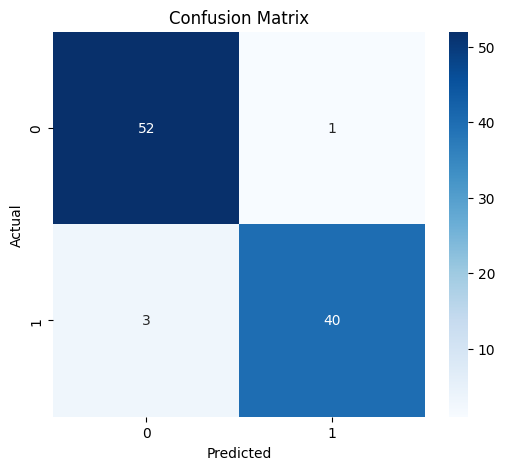

In [ ]:
# Evaluate Model

y_pred_prob = model.predict(X_test)

y_pred = (y_pred_prob > 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

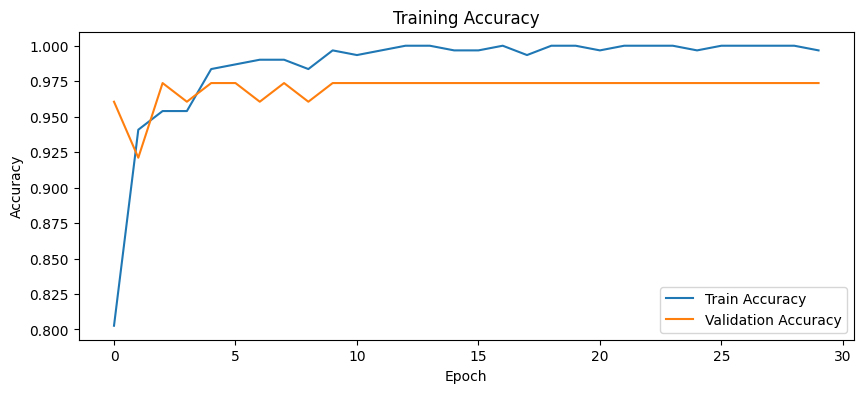

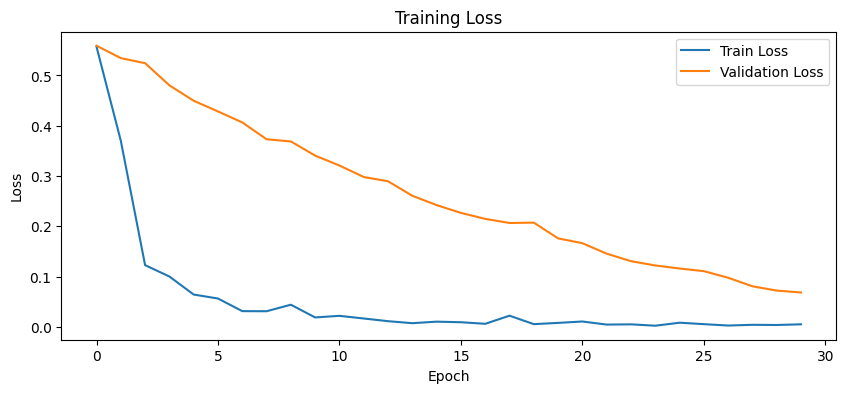

In [ ]:
# Plot Training Curves

plt.figure(figsize=(10,4))

plt.plot(
    history.history['accuracy'],
    label='Train Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy")

plt.legend()
plt.show()


plt.figure(figsize=(10,4))

plt.plot(
    history.history['loss'],
    label='Train Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")

plt.legend()
plt.show()

In [ ]:
# Save Keras model

model.save("fall_detection_model.h5")

print("H5 model saved successfully")

H5 model saved successfully


In [ ]:
# Convert to TensorFlow Lite

converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_model = converter.convert()

with open("fall_detection_model.tflite", "wb") as f:
    f.write(tflite_model)

print("TFLite model saved successfully")

Saved artifact at '/tmp/tmpud2l7n1t'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  132762001582288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132762001584976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132762001586896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132762001584592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132762001584400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132762001585936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132762001587856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132762001588048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132762001586128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132762001587664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132762001586704: Te